In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style='whitegrid')

# Load the dataset
df = pd.read_csv('../data/raw_customer_data.csv')

# Inspect shape and first few rows
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Matplotlib is building the font cache; this may take a moment.


Dataset Shape: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Convert 'TotalCharges' from string to numeric (handles empty spaces)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

# Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Convert Churn ('Yes'/'No') to numeric binary (1/0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Check summary of cleaned data
df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].describe()

,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,0.265370
std,24.559481,30.090047,2266.794470,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,398.550000,0.000000
50%,29.000000,70.350000,1394.550000,0.000000
75%,55.000000,89.850000,3786.600000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


C:\Users\223933-EQ0024AU\AppData\Local\Temp\ipykernel_13344\4105599202.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Churn', data=df, palette='Blues_r')


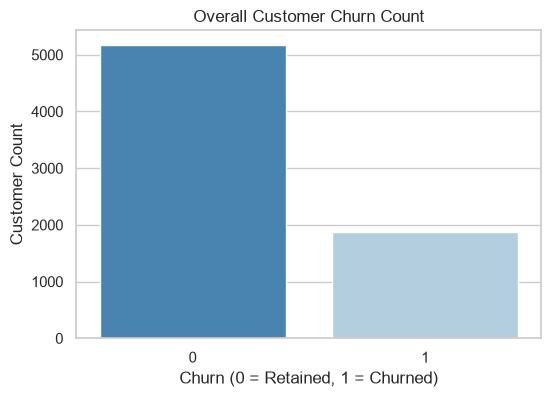

Overall Churn Rate: 26.54%


In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn', data=df, palette='Blues_r')
plt.title('Overall Customer Churn Count')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Customer Count')
plt.show()

churn_rate = df['Churn'].mean() * 100
print(f"Overall Churn Rate: {churn_rate:.2f}%")

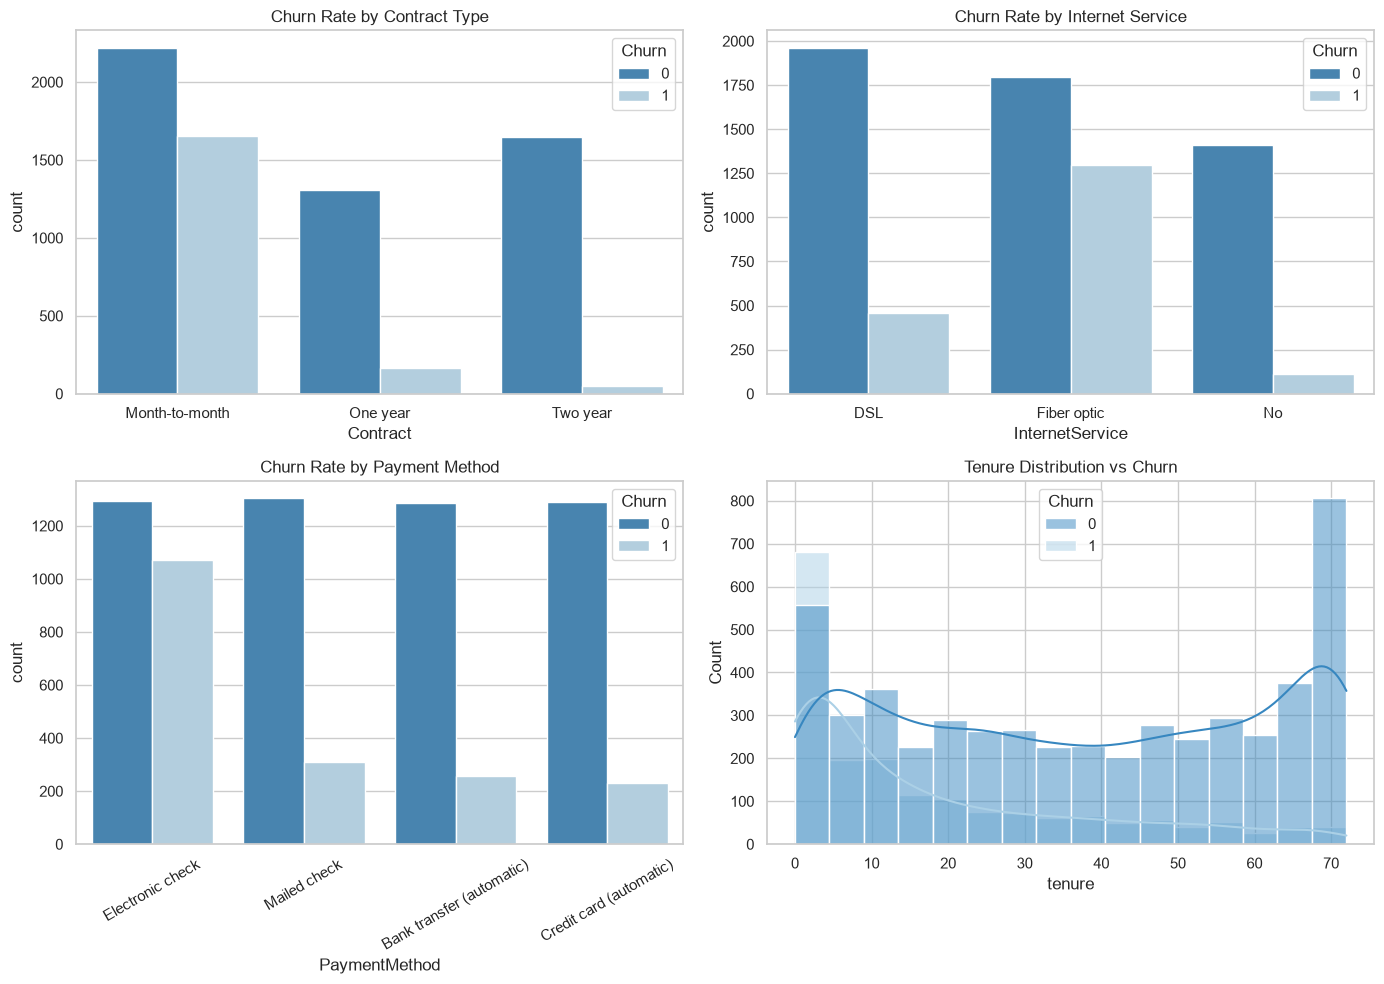

In [4]:
# Set up a grid for multiple plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Churn by Contract Type
sns.countplot(x='Contract', hue='Churn', data=df, ax=axes[0,0], palette='Blues_r')
axes[0,0].set_title('Churn Rate by Contract Type')

# 2. Churn by Internet Service
sns.countplot(x='InternetService', hue='Churn', data=df, ax=axes[0,1], palette='Blues_r')
axes[0,1].set_title('Churn Rate by Internet Service')

# 3. Churn by Payment Method
sns.countplot(x='PaymentMethod', hue='Churn', data=df, ax=axes[1,0], palette='Blues_r')
axes[1,0].tick_params(axis='x', rotation=30)
axes[1,0].set_title('Churn Rate by Payment Method')

# 4. Tenure Distribution (How long customers stay)
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[1,1], palette='Blues_r')
axes[1,1].set_title('Tenure Distribution vs Churn')

plt.tight_layout()
plt.show()